# BEN2 demo: cut out the subject, put it on a hex colour

Pick an image from `data/` by name, predict a soft mask with BEN2, composite the subject over a plain colour. Confidence-guided matting model (MIT licence on the model card).

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib import colors as mcolors
from PIL import Image, ImageOps
from ben2 import BEN_Base

# Repo root = first parent folder that holds requirements.txt (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA = ROOT / "data"
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32  # fp16 is slow / unsupported on CPU
print("repo:", ROOT, "| device:", device, dtype)

repo: c:\Users\DELL\Desktop\modelia.ai\task1\modelia-bg-change | device: cpu torch.float32


## Hex helper

The 148 CSS colour names, from matplotlib (no hand-typed table). `hex_of("blue")` lists every name containing *blue* with its hex.

In [13]:
def hex_of(name: str) -> None:
    """Print the CSS colours whose name contains `name`."""
    for n, h in sorted(mcolors.CSS4_COLORS.items()):
        if name.lower() in n:
            print(f"{n:22s} {h}")

hex_of("blue")

aliceblue              #F0F8FF
blue                   #0000FF
blueviolet             #8A2BE2
cadetblue              #5F9EA0
cornflowerblue         #6495ED
darkblue               #00008B
darkslateblue          #483D8B
deepskyblue            #00BFFF
dodgerblue             #1E90FF
lightblue              #ADD8E6
lightskyblue           #87CEFA
lightsteelblue         #B0C4DE
mediumblue             #0000CD
mediumslateblue        #7B68EE
midnightblue           #191970
powderblue             #B0E0E6
royalblue              #4169E1
skyblue                #87CEEB
slateblue              #6A5ACD
steelblue              #4682B4


## Settings

In [14]:
IMAGE_NAME = "Bag"    # any part of the file name, case-insensitive
BG_HEX = "#FFFFFF"     # with or without '#', 3 or 6 digits

In [15]:
def parse_hex(s: str) -> tuple[int, int, int]:
    """'#1E90FF', '1e90ff', '#fff' -> (r, g, b)."""
    s = s.strip().lstrip("#")
    if len(s) == 3:
        s = "".join(c * 2 for c in s)  # 'fff' -> 'ffffff'
    if len(s) != 6:
        raise ValueError(f"bad hex colour: {s!r}")
    return tuple(int(s[i:i + 2], 16) for i in (0, 2, 4))

def find_image(name: str) -> Path:
    """First image under data/ whose file name contains `name`, ground-truth masks excluded."""
    hits = sorted(p for p in DATA.rglob("*")
                  if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
                  and "gt" not in p.parent.name.lower()
                  and name.lower() in p.name.lower())
    if not hits:
        raise FileNotFoundError(f"no image matching {name!r} in {DATA}")
    if len(hits) > 1:
        print(f"{len(hits)} matches, using the first:", *[h.name for h in hits[:10]], sep="\n  ")
    return hits[0]

bg_rgb = parse_hex(BG_HEX)
path = find_image(IMAGE_NAME)
img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")  # fix phone rotation, drop alpha/gray
print(path.name, img.size, "->", bg_rgb)

4 matches, using the first:
  1#Accessories#1#Bag#3811492306_4ae60c73b6_o.jpg
  1#Accessories#1#Bag#6815402415_e01c1a41e6_o.jpg
  1#Accessories#1#Bag#8567416130_6dba65c649_o.jpg
  20#Sports#7#Punchbag#12510276823_236b230c98_o.jpg
1#Accessories#1#Bag#3811492306_4ae60c73b6_o.jpg (2592, 3872) -> (255, 255, 255)


In [16]:
path = ROOT / "data" / "PPM-100" / "image" / "5475151559_0245f5ca69_o.jpg"
print(path)
img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")

c:\Users\DELL\Desktop\modelia.ai\task1\modelia-bg-change\data\PPM-100\image\5475151559_0245f5ca69_o.jpg


## Load BEN2

Not on PyPI: install the package from GitHub first (run once, then restart the kernel):

`pip install -e "git+https://github.com/PramaLLC/BEN2.git#egg=ben2"`

The weights download from the Hugging Face repo `PramaLLC/BEN2` on first use.

In [17]:
model = BEN_Base.from_pretrained("PramaLLC/BEN2")
model.to(device).eval()

BEN_Base(
  (backbone): SwinTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (pos_drop): Dropout(p=0.0, inplace=True)
    (layers): ModuleList(
      (0): BasicLayer(
        (blocks): ModuleList(
          (0): SwinTransformerBlock(
            (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
            (attn): WindowAttention(
              (qkv): Linear(in_features=128, out_features=384, bias=True)
              (attn_drop): Dropout(p=0.0, inplace=True)
              (proj): Linear(in_features=128, out_features=128, bias=True)
              (proj_drop): Dropout(p=0.0, inplace=True)
              (softmax): Softmax(dim=-1)
            )
            (drop_path): Identity()
            (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
            (mlp): Mlp(
              (fc1): Linear(in_fe

## Predict the soft mask

In [18]:
def predict_alpha(img: Image.Image) -> np.ndarray:
    """Float alpha in [0, 1] at the image's original size."""
    fg = model.inference(img.copy(), refine_foreground=False)  # copy: BEN2 calls putalpha() on its input in place
    return np.asarray(fg.getchannel("A"), np.float32) / 255

%time alpha = predict_alpha(img)
print("alpha range:", alpha.min().round(3), alpha.max().round(3))

CPU times: total: 1min 29s
Wall time: 23.6 s
alpha range: 0.0 1.0


## Composite: `out = alpha * image + (1 - alpha) * colour` (Porter-Duff *over*)

ground truth: c:\Users\DELL\Desktop\modelia.ai\task1\modelia-bg-change\data\PPM-100\matte\5475151559_0245f5ca69_o.jpg


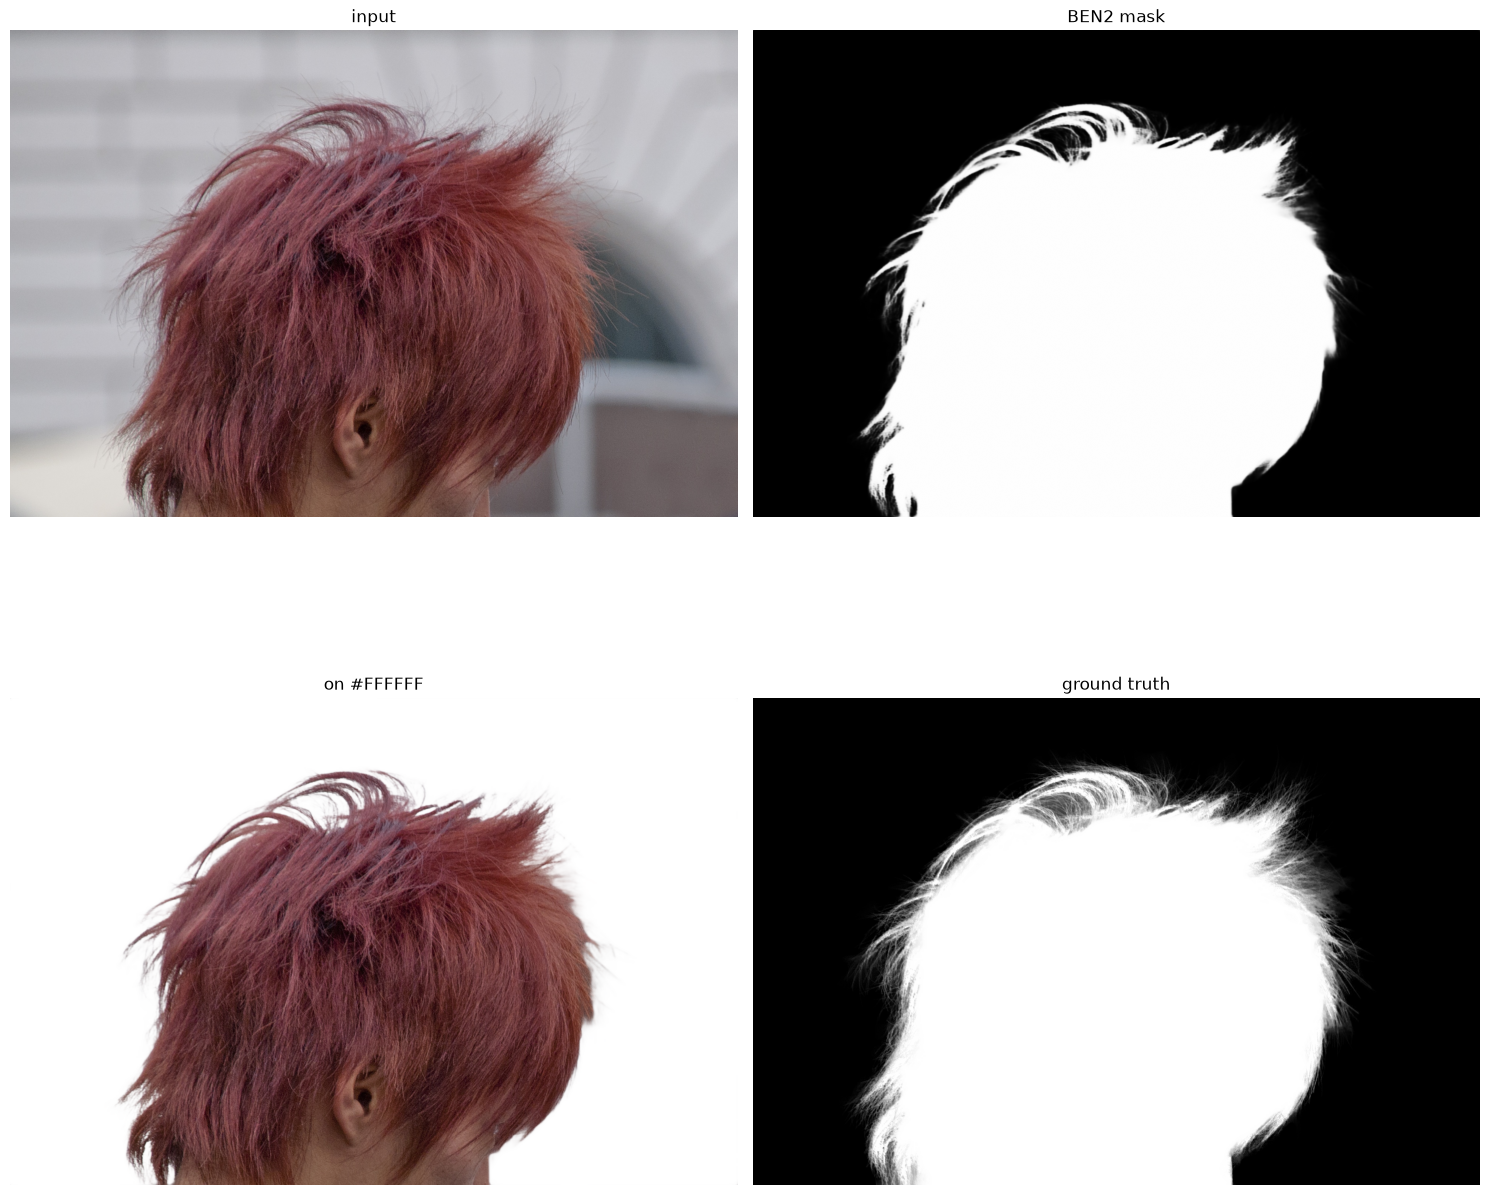

In [ ]:
a = alpha[..., None]
out = a * np.asarray(img, np.float32) + (1 - a) * np.array(bg_rgb, np.float32)
out = Image.fromarray(out.round().astype(np.uint8))


gt_path = path.parent.parent / "matte" / path.with_suffix(".jpg").name
print("ground truth:", gt_path)
try:
    gt = Image.open(gt_path)
except FileNotFoundError:
    gt = Image.open(ROOT / "Black.png")

fig, ax = plt.subplots(2, 2, figsize=(15, 15))
for axis, im, title, cmap in [(ax[0][0], img, "input", None),
                              (ax[0][1], alpha, "BEN2 mask", "gray"),
                              (ax[1][0], out, f"on {BG_HEX}", None),
                              (ax[1][1], gt, "ground truth", "gray")]:
    axis.imshow(im, cmap=cmap)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()